In [2]:
# code here
import cv2
import matplotlib.pyplot as plt
import numpy as np

1)	A partir da imagem original obtenha as outras imagens conforme descrição

Desejamos separar linhas de círculos. Uma operação de abertura com um elemento estruturante na forma de círculo (definir o raio) faz essa tarefa. Gere uma imagem com os círculos e uma com as linhas


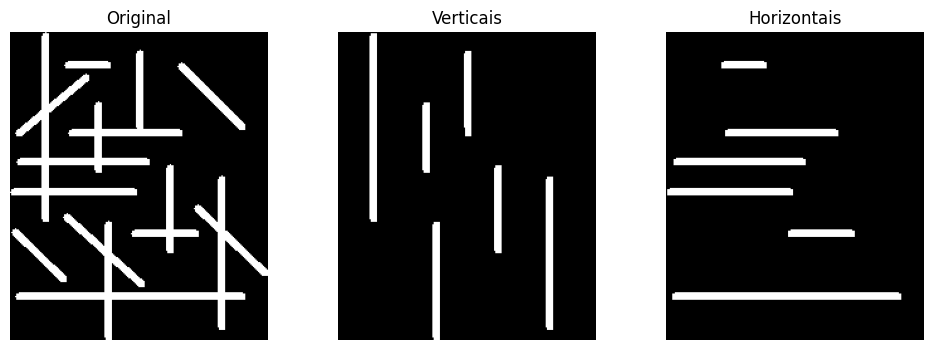

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def erosao(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=255)

    saida = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            regiao = img_padded[i:i+kh, j:j+kw]

            # Só mantém branco se TODOS os pixels do kernel forem brancos
            if np.all(regiao[kernel == 1] == 255):
                saida[i, j] = 255
            else:
                saida[i, j] = 0

    return saida


def dilatacao(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)

    saida = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            regiao = img_padded[i:i+kh, j:j+kw]

            # Se QUALQUER pixel do kernel for branco → vira branco
            if np.any(regiao[kernel == 1] == 255):
                saida[i, j] = 255
            else:
                saida[i, j] = 0

    return saida


def abertura(img, kernel):
    erodida = erosao(img, kernel)
    dilatada = dilatacao(erodida, kernel)
    return dilatada


img1 = cv2.imread("art3.png", cv2.IMREADGRAYSCALE)

Binarização
, bin = cv2.threshold(img1, 127, 255, cv2.THRESH_BINARY)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (8, 8))

Abertura
circulos = abertura(bin, kernel)

Linhas
linhas = cv2.subtract(bin, circulos)

Plot
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.title("Original")
plt.imshow(img1, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title("Círculos")
plt.imshow(circulos, cmap='gray')
plt.axis('off')

plt.subplot(1,3,3)
plt.title("Linhas")
plt.imshow(linhas, cmap='gray')
plt.axis('off')

plt.show()


2)

a) Obter linhas verticais. Abertura com elemento estruturante vertical 3x9
b) Obter linhas horizontais. Abertura com elemento estruturante horizontal 9x3. Tente eliminar as linhas erradas usando uma máscara maior


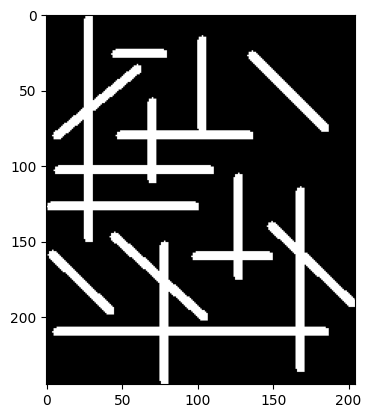

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# ----------- Funções de morfologia -----------

def erosao(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)),
                        mode='constant', constant_values=255)

    saida = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            regiao = img_padded[i:i+kh, j:j+kw]

            if np.all(regiao[kernel == 1] == 255):
                saida[i, j] = 255

    return saida


def dilatacao(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)),
                        mode='constant', constant_values=0)

    saida = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            regiao = img_padded[i:i+kh, j:j+kw]

            if np.any(regiao[kernel == 1] == 255):
                saida[i, j] = 255

    return saida


def abertura(img, kernel):
    return dilatacao(erosao(img, kernel), kernel)

# ----------- Código principal -----------

img2 = cv2.imread("art2.png", cv2.IMREAD_GRAYSCALE)

# Binarização
_, bin = cv2.threshold(img2, 127, 255, cv2.THRESH_BINARY)

# ---------------------------
# LINHAS VERTICAIS
# ---------------------------
kernel_v = cv2.getStructuringElement(cv2.MORPH_RECT, (3,9))
verticais = abertura(bin, kernel_v)

# Refinamento
kernel_v2 = cv2.getStructuringElement(cv2.MORPH_RECT, (3,15))
verticais = abertura(verticais, kernel_v2)

# ---------------------------
# LINHAS HORIZONTAIS
# ---------------------------
kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (9,3))
horizontais = abertura(bin, kernel_h)

# Refinamento
kernel_h2 = cv2.getStructuringElement(cv2.MORPH_RECT, (15,3))
horizontais = abertura(horizontais, kernel_h2)

# ---------------------------
# PLOT
# ---------------------------
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Original")
plt.imshow(img2, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title("Verticais")
plt.imshow(verticais, cmap='gray')
plt.axis('off')

plt.subplot(1,3,3)
plt.title("Horizontais")
plt.imshow(horizontais, cmap='gray')
plt.axis('off')

plt.show()

3)

a) Theshold (t=210)

b) Utilizando abertura com elemento circular de 11 pixels para reter as células grandes

c) É possível reter somente os objetos pequenos utilizando a operação abertura?

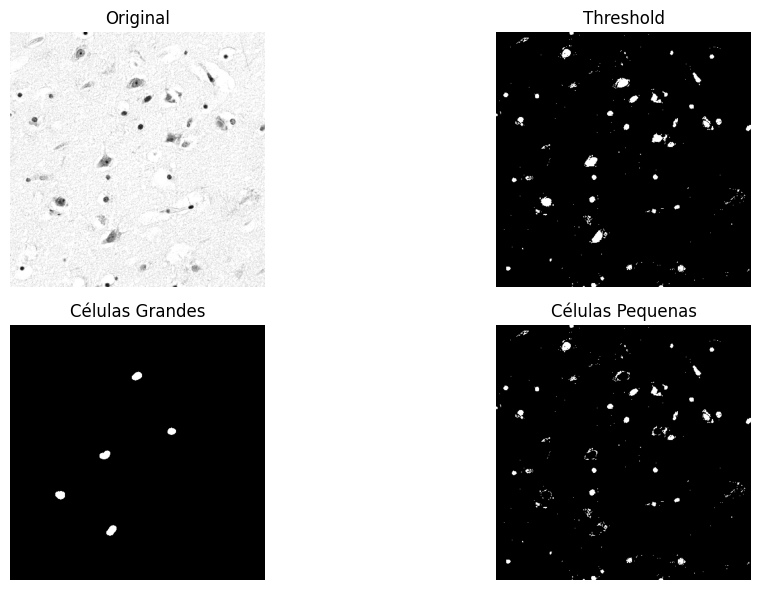

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def erosao(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)),
                        mode='constant', constant_values=0)

    saida = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            regiao = img_padded[i:i+kh, j:j+kw]
            if np.all(regiao[kernel == 1] == 255):
                saida[i, j] = 255

    return saida

def dilatacao(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)),
                        mode='constant', constant_values=0)

    saida = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            regiao = img_padded[i:i+kh, j:j+kw]
            if np.any(regiao[kernel == 1] == 255):
                saida[i, j] = 255

    return saida

def abertura(img, kernel):
    return dilatacao(erosao(img, kernel), kernel)


img3 = cv2.imread("cel4.png", cv2.IMREAD_GRAYSCALE)

# a) Threshold 
_, th = cv2.threshold(img3, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# b) Kernel elíptico
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11,11))

# Abertura
grandes = abertura(th, kernel)

# c) Pequenos
pequenos = cv2.subtract(th, grandes)

# -------------------------
# PLOT
# -------------------------
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.title("Original")
plt.imshow(img3, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("Threshold")
plt.imshow(th, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Células Grandes")
plt.imshow(grandes, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Células Pequenas")
plt.imshow(pequenos, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

4)
Utilizando os conceitos já aprendidos na disciplina, faça um código que calcula a quantidade de objetos da imagem abaixo. Pode-se utilizar funções prontas do opencv (não para realizar a contagem em si, mas para realizar os passos necessários)

Quantidade de feijões detectados: 95


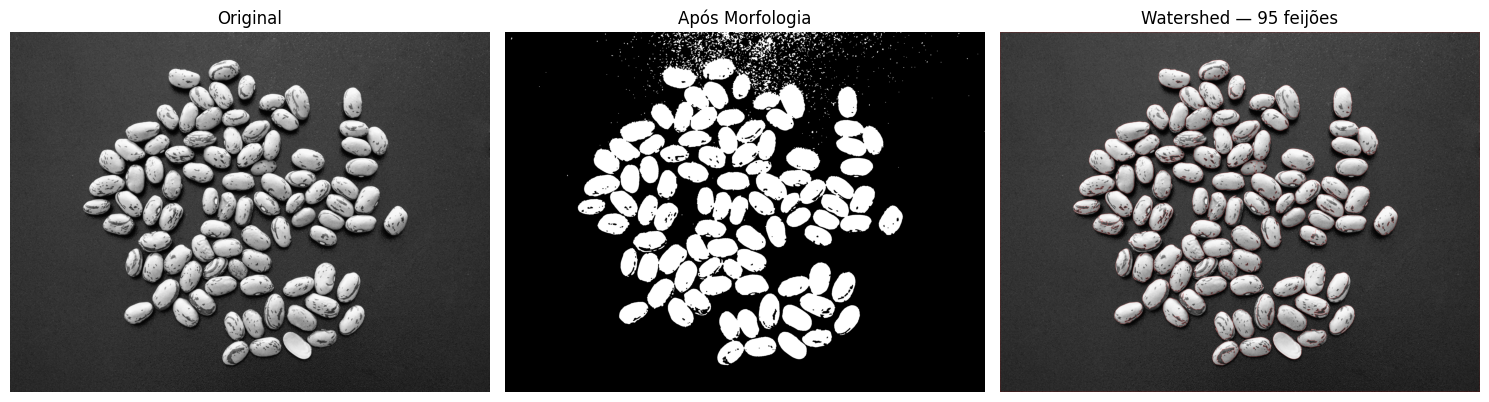

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img4 = cv2.imread("feijao.jpg", cv2.IMREAD_GRAYSCALE)

_, thresh = cv2.threshold(img4, 80, 255, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=3)
morph = cv2.morphologyEx(morph, cv2.MORPH_OPEN, kernel, iterations=2)

dist_transform = cv2.distanceTransform(morph, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist_transform, 0.4 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

sure_bg = cv2.dilate(morph, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

img_color = cv2.cvtColor(img4, cv2.COLOR_GRAY2BGR)
markers = cv2.watershed(img_color, markers)

num_feijoes = len(np.unique(markers)) - 2
print(f"Quantidade de feijões detectados: {num_feijoes}")

img_resultado = img_color.copy()
img_resultado[markers == -1] = [0, 0, 255]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(img4, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Após Morfologia")
plt.imshow(morph, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title(f"Watershed — {num_feijoes} feijões")
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

5.  Utilize a transformada hit or miss para localizar o logotipo da UFU. Escolha um deles

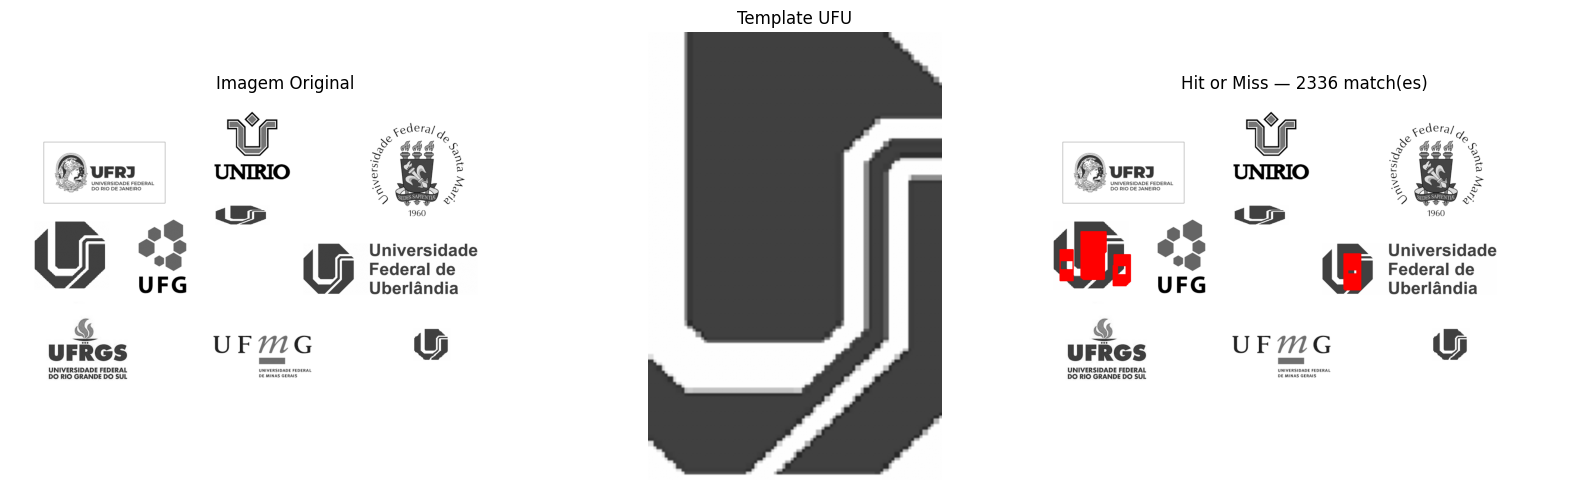

In [4]:
img5 = cv2.imread("logotipos.png", cv2.IMREAD_GRAYSCALE)

template_region = img5[300:460, 95:200]

_, img_bin = cv2.threshold(img5, 127, 1, cv2.THRESH_BINARY_INV)
_, tmpl_bin = cv2.threshold(template_region, 127, 1, cv2.THRESH_BINARY_INV)

scale = 0.3
th = int(tmpl_bin.shape[0] * scale)
tw = int(tmpl_bin.shape[1] * scale)
kernel_hit = cv2.resize(tmpl_bin.astype(np.float32), (tw, th))
_, kernel_hit = cv2.threshold(kernel_hit, 0.5, 1, cv2.THRESH_BINARY)
kernel_hit = kernel_hit.astype(np.int8)

hitmiss = cv2.morphologyEx(img_bin.astype(np.uint8), cv2.MORPH_HITMISS, kernel_hit)

locations = np.where(hitmiss > 0)
img_resultado = cv2.cvtColor(img5, cv2.COLOR_GRAY2BGR)

h, w = kernel_hit.shape
for pt in zip(locations[1], locations[0]):
    cv2.rectangle(img_resultado, pt, (pt[0] + w, pt[1] + h), (0, 0, 255), 2)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.title("Imagem Original")
plt.imshow(img5, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Template UFU")
plt.imshow(template_region, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title(f"Hit or Miss — {len(locations[0])} match(es)")
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

6. Utilize operadores morfológicos para extração de fronteiras dos feijões. Mostre o resultado junto com a imagem original

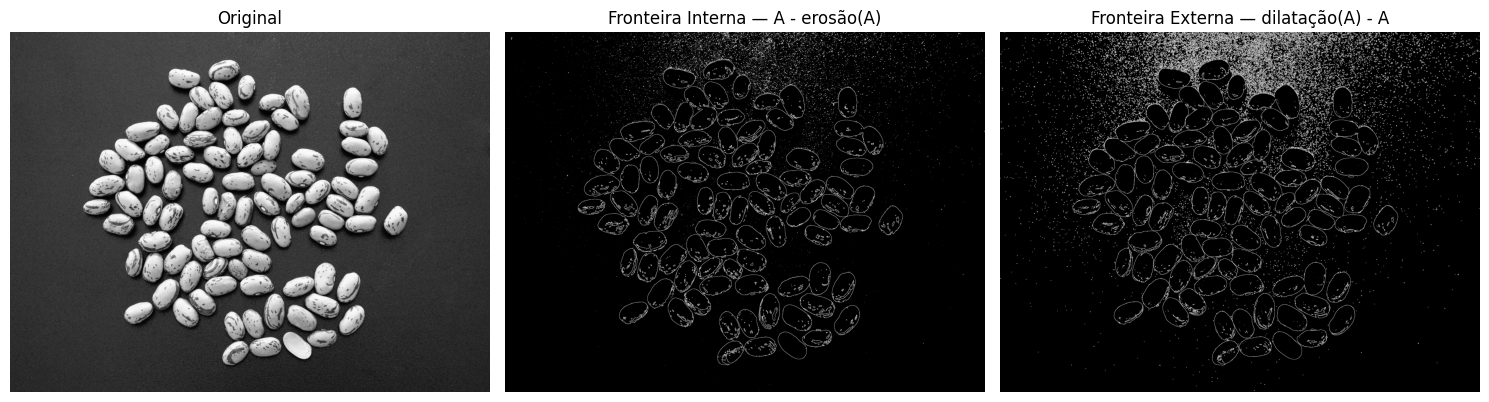

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img4 = cv2.imread("feijao.jpg", cv2.IMREAD_GRAYSCALE)

_, img_bin = cv2.threshold(img4, 80, 255, cv2.THRESH_BINARY)

kernel = np.ones((5, 5), np.uint8)
erosao    = cv2.erode(img_bin, kernel, iterations=1)
dilatacao = cv2.dilate(img_bin, kernel, iterations=1)

fronteira_interna = cv2.subtract(img_bin, erosao)
fronteira_externa = cv2.subtract(dilatacao, img_bin)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(img4, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Fronteira Interna — A - erosão(A)")
plt.imshow(fronteira_interna, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Fronteira Externa — dilatação(A) - A")
plt.imshow(fronteira_externa, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.tight_layout()
plt.show()